In [7]:
#%pip install pandas matplotlib geopy pyproj openpyxl
import pandas as pd
import matplotlib.pyplot as plt
from geopy.distance import geodesic
from datetime import datetime
from pyproj import Transformer
import random


In [8]:
data = pd.read_excel("anomalies_corrected_data.xlsx", sheet_name="Data")

# Understanding each feature

### Meaning of features

step - index of data point

rat_id - radio access technology id, 23 could be 4G and 5G, 6 means 4G

eci_nci - ECI (E-UTRAN Cell Identity) is a 28-bit cell identifier used in 4G LTE networks,
NCI (NR Cell Identity) is a 36-bit cell identifier used in 5G New Radio (NR) networks.
If eci can be translated into less then or equal 28-bit then eci else nci

network - 4G or 5G technology

timestamp - when this happened. Measured with 1 microsecond resolution and in UTC timezone. 
(example: 2025-12-24T00:11:07.044096Z - 2025-12-24 year/month/day, 00:11:07.044096Z - hours/minutes/seconds)

latitude - cell latitude coordinate

longitude - cell longitude coordinate

geometry_type - ARC means cell covers a sector, CIRCLE means cell covers 0 - 360 degrees

start_angle - coverage sector start angle (for circle it is always 0)

end_angle - coverage sector end angle (for circle it is always 360)

outer_radius - defines the accuracy of the location in meters

inner_radius - unimportant, dont know what, but in our dataset always 0

cell_updated_flag - dont know what, depends on device_interface_type

device_interface_type - what interface the cell implements (S1_MME for 4G and N1, N11 for 5G)

server - node that processed that event

application_name - protocols

message_name - event name

apn_name - application name - ims, ota or pda





In [9]:
#Assumptions:

#check whether S1_MME is ONLY for 4G and N1, N11 are ONLY for 5G
def assumption1():
    check1 = len(data[data["device_interface_type"] == "S1_MME"]["device_interface_type"].value_counts())
    check2 = len(data[data["device_interface_type"] == "N1"]["device_interface_type"].value_counts())
    check3 = len(data[data["device_interface_type"] == "N11"]["device_interface_type"].value_counts())

    if all([x == 1 for x in [check1, check2, check3]]):
        print("Correct assumption")
#assumption1()

#check whether each cell is tied with exactly one location
def assumption2():
    flag = True
    for i in data["eci_nci"]: 
        counts = data[data["eci_nci"] == i][["longitude", "latitude"]].value_counts()
        if len(counts) > 1:
            flag = False
    if flag:
        print("Correct assumption")
#assumption2()

In [10]:
#check each feature if there exist Nan or None or missing values, return list of feature/features if there is
def faulty_feature_values():
    faulty_features = []
    for feature in data.columns:
        if data[feature].isna().sum() > 0:
            faulty_features.append(feature)
    if len(faulty_features) > 0:
        print("Missing values in these features: ", ", ".join(faulty_features))
    return faulty_features
faulty_feature_values()

Missing values in these features:  cell_updated_flag, apn_name


['cell_updated_flag', 'apn_name']

Missing values in these features:  cell_updated_flag, apn_name


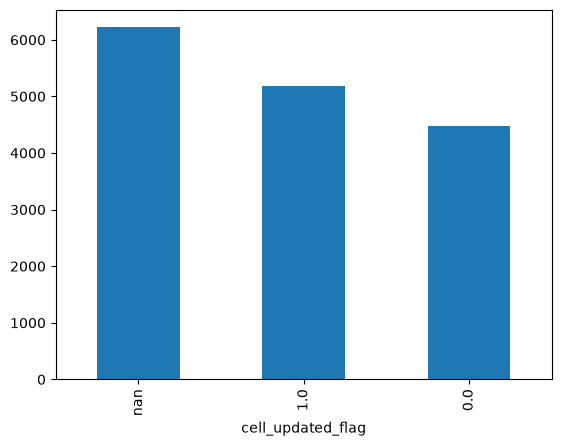

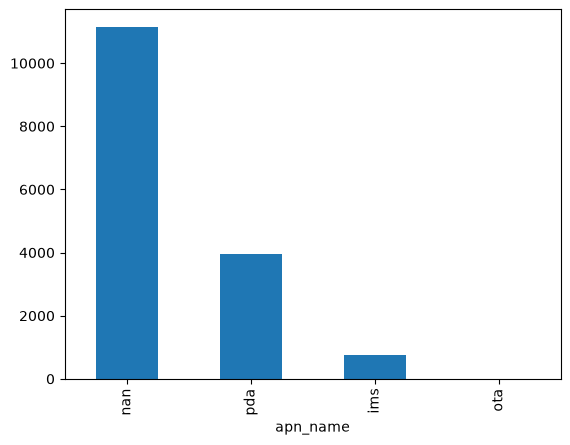

In [11]:
#Further explore those features which have missing values
faulty_features = faulty_feature_values()
if faulty_features:
    for col in faulty_features:
        data[col].value_counts(dropna=False).plot(kind="bar")
        plt.show()
        


Index(['step', 'rat_id', 'eci_nci', 'network', 'timestamp', 'latitude',
       'longitude', 'geometry_type', 'start_angle', 'end_angle',
       'outer_radius', 'inner_radius', 'cell_updated_flag',
       'device_interface_type', 'server', 'application_name', 'message_name',
       'apn_name'],
      dtype='str')


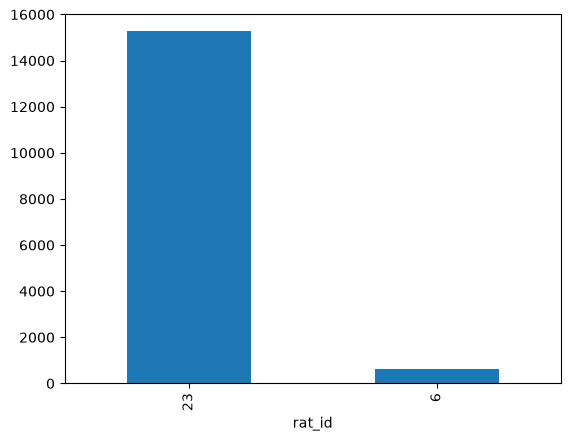

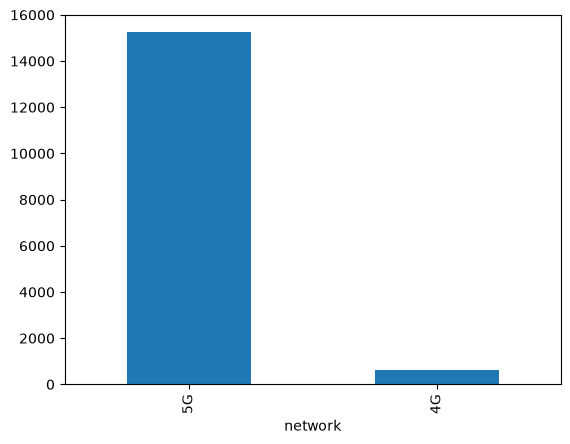

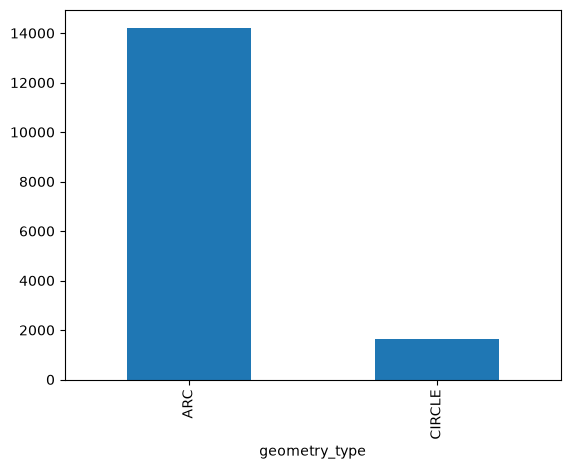

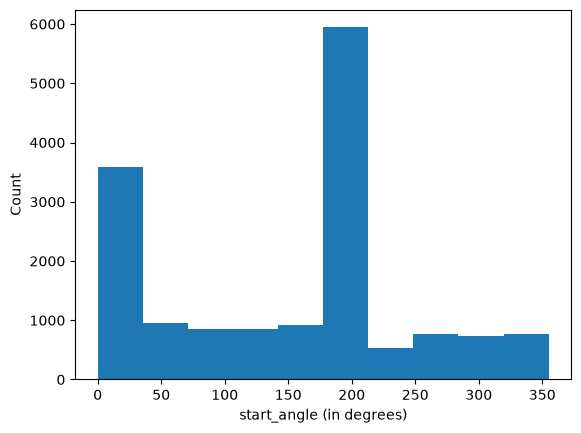

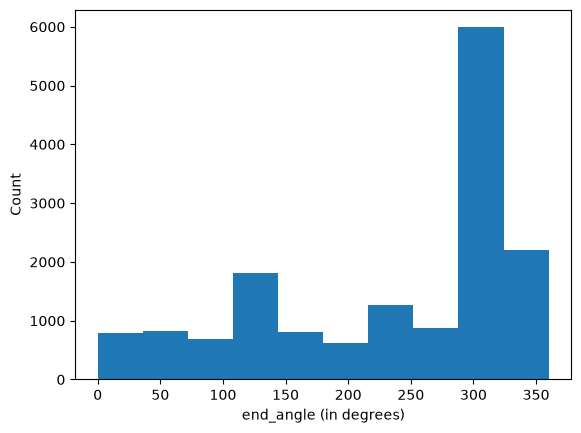

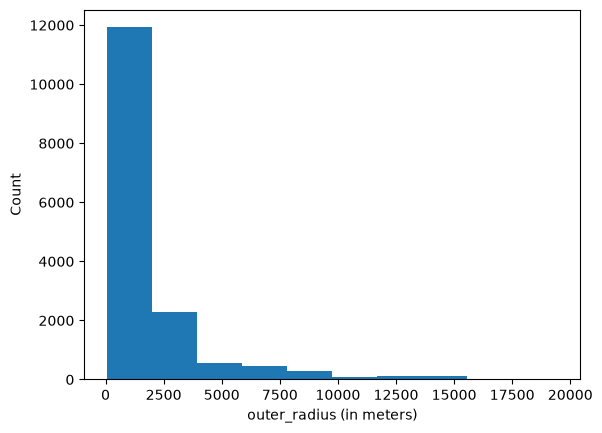

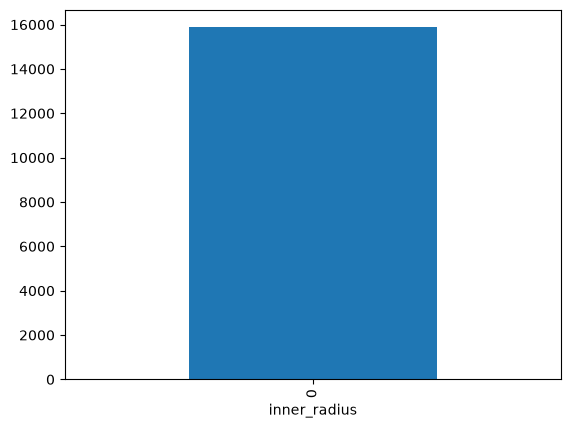

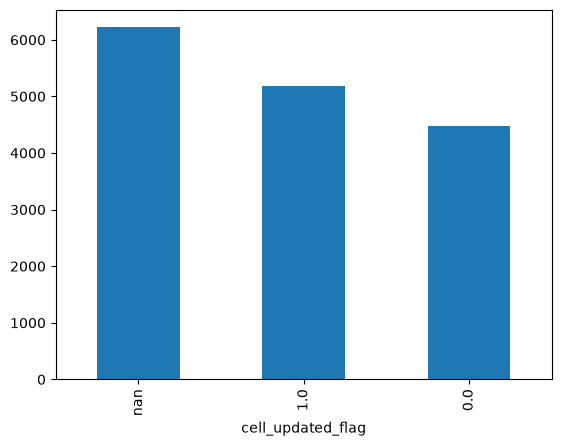

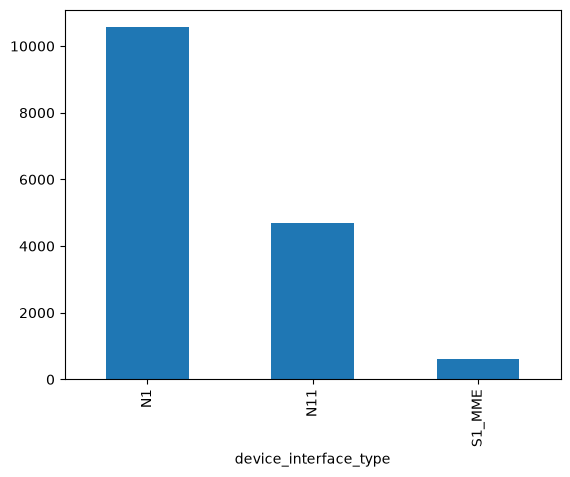

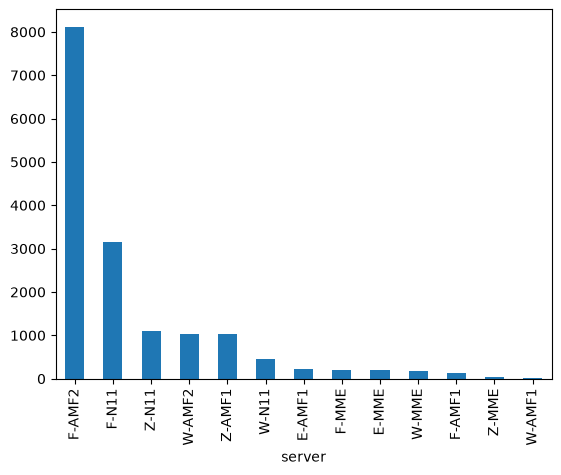

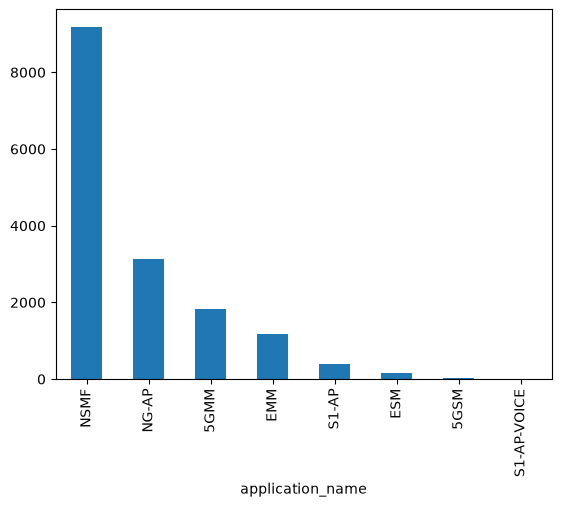

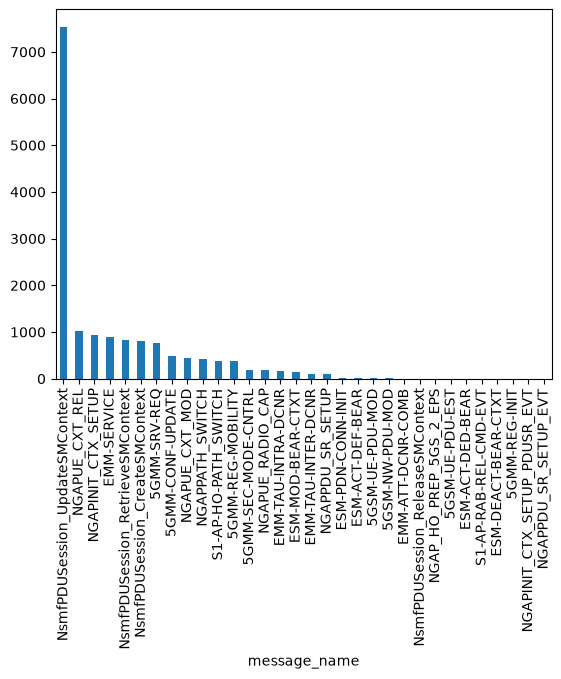

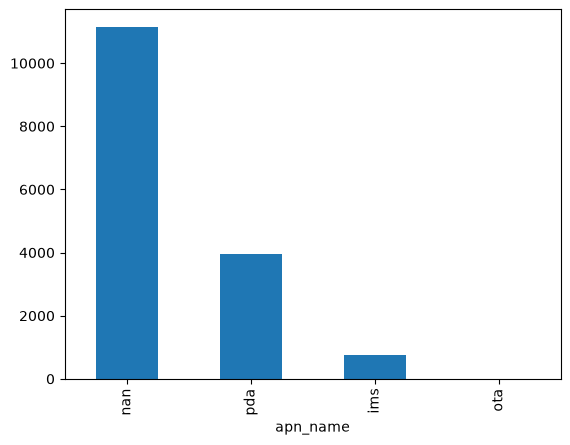

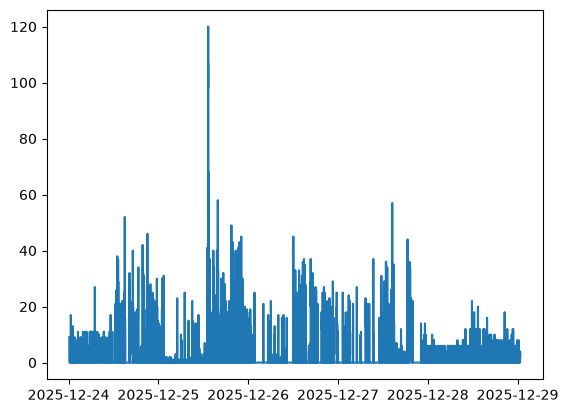

In [44]:
#Plotting each feature value_counts
print(data.columns)

features = ["rat_id", "network", "geometry_type", "start_angle", 
            "end_angle", "outer_radius", "inner_radius", "cell_updated_flag",
            "device_interface_type", "server", "application_name", "message_name", "apn_name"] 

#exluded features from plotting: step, eci_nci, timestamp, latitude, longitude
metrics = {"start_angle" : "in degrees", "end_angle" : "in degrees", "outer_radius" : "in meters"}
for col in features:
    #special treatment for certain features
    if col in set(["start_angle", "end_angle", "outer_radius"]):
        plt.hist(x=data[col], bins=10)
        plt.xlabel(f"{col} ({metrics[col]})")
        plt.ylabel("Count")
        plt.show()
    else:
        data[col].value_counts(dropna=False).plot(kind="bar")
        plt.show()
    
#records density on timescale

data["timestamp"] = pd.to_datetime(data["timestamp"])
density = data.set_index("timestamp").resample("1min").size()

plt.plot(density)
plt.show()



In [ ]:
data["distances"] = [geodesic(
        (data["latitude"].iloc[i], data["longitude"].iloc[i]),
        (data["latitude"].iloc[i+1], data["longitude"].iloc[i+1])
        ).m for i in range(len(data)-1)] + [None] #plus None because the comparision shirnks the data into len(data)-1

data["delta_time"] = [data["timestamp"].iloc[i+1] - 
                      data["timestamp"].iloc[i] for i in range(len(data)-1)] + [None]

data["margin_error"] = [data["outer_radius"].iloc[i] + 
                        data["outer_radius"].iloc[i+1] for i in range(len(data)-1)] + [None]

data["margin_error_squared"] = [(data["outer_radius"].iloc[i] +
                                data["outer_radius"].iloc[i+1])**2 for i in range(len(data)-1)] + [None]

#count jumps that are not in margin_error_squared - that means anomalies ????
anomaly_count = data[data["distances"] > data["margin_error"]]
print(anomaly_count)

data = data[:-1].copy() #leave out the last because distance value is None

        step  rat_id      eci_nci network                        timestamp  \
777      778      23  16385097770      5G 2025-12-24 12:43:53.571933+00:00   
795      796      23  16385146923      5G 2025-12-24 12:45:17.256156+00:00   
800      801      23  16385097770      5G 2025-12-24 12:45:20.442826+00:00   
801      802      23  16385146923      5G 2025-12-24 12:45:24.686706+00:00   
806      807      23  16385097770      5G 2025-12-24 12:45:32.325253+00:00   
...      ...     ...          ...     ...                              ...   
13778  13779      23  16385933313      5G 2025-12-27 19:08:15.344746+00:00   
13779  13780      23  16386064385      5G 2025-12-27 19:08:15.405097+00:00   
14133  14134      23  16384933929      5G 2025-12-27 19:41:36.514148+00:00   
14134  14135      23  16385736705      5G 2025-12-27 19:41:36.514252+00:00   
14206  14207      23  16385196054      5G 2025-12-27 19:51:22.904009+00:00   

        latitude  longitude geometry_type  start_angle  end_ang

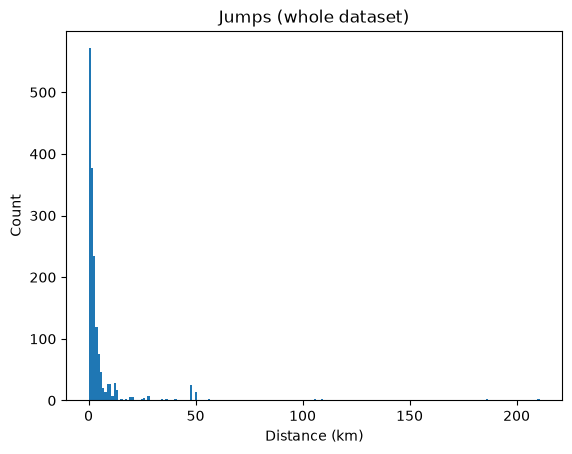

10.181311374627557


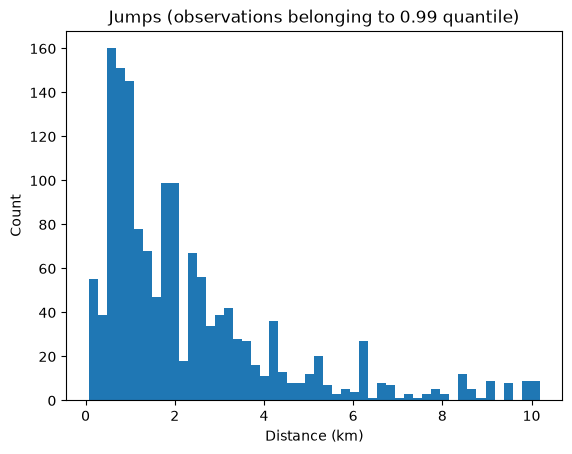

In [ ]:
sub_data = data[data["distances"] != 0]
plt.hist(sub_data["distances"], bins=200)
plt.xlabel("Distance (km)")
plt.ylabel("Count")
plt.title("Jumps (whole dataset)")
plt.show()

quantile_value = data["distances"].quantile(0.99)
print(quantile_value)

sub_data = data[(data["distances"] != 0) & (data["distances"] <= quantile_value)]
plt.hist(sub_data["distances"], bins=50)
plt.xlabel("Distance (km)")
plt.ylabel("Count")
plt.title("Jumps (observations belonging to 0.99 quantile)") #distance = (timestep t+1 location) - (timestep t location)
plt.show()

Shows that 99% percent of data points are in the range from 0km -10.18 km

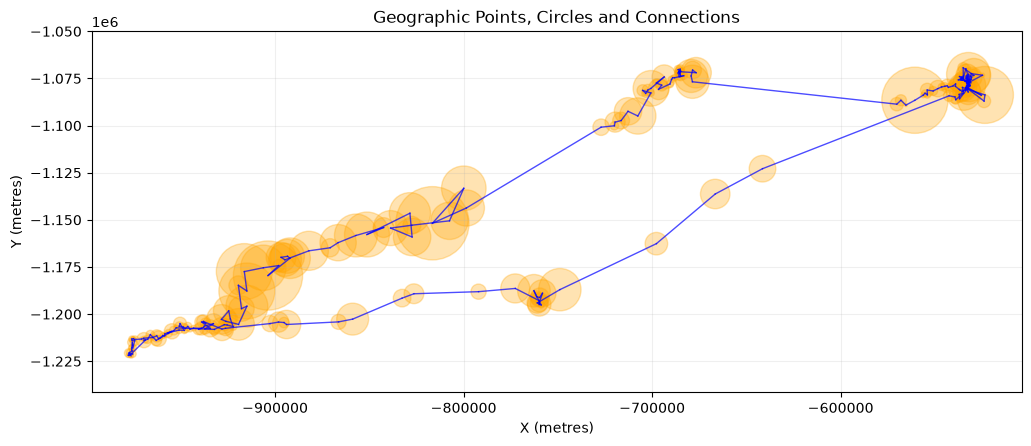

In [ ]:

sub_data = data.drop_duplicates(subset=["latitude", "longitude"]).head(600)

latitude, longitude, outer_radius = sub_data["latitude"], sub_data["longitude"], sub_data["outer_radius"]

transformer = Transformer.from_crs("EPSG:4326", "EPSG:5514", always_xy=True) #input, output

x_vals, y_vals = transformer.transform(longitude, latitude)

fig, ax = plt.subplots(figsize=(12, 10))

for i in range(len(sub_data)-1):

    x, y, r = x_vals[i], y_vals[i], outer_radius.iloc[i]

    x_next, y_next, r_next = x_vals[i+1], y_vals[i+1], outer_radius.iloc[i+1]

    circle = plt.Circle((x, y), radius=r, facecolor="orange", alpha=0.3, edgecolor="orange")

    ax.add_patch(circle)

    ax.plot([x, x_next], [y, y_next], color="blue", linewidth=1, alpha=0.7, zorder=2)

max_radius = outer_radius.max()

ax.set_xlim(min(x_vals) - max_radius, max(x_vals) + max_radius) #sets the x-axis value range
ax.set_ylim(min(y_vals) - max_radius, max(y_vals) + max_radius) #sets the y-axis value range

ax.set_aspect("equal")
ax.set_xlabel("X (metres)")
ax.set_ylabel("Y (metres)")
ax.set_title("Geographic Points, Circles and Connections")
ax.grid(alpha=0.2)

plt.show()


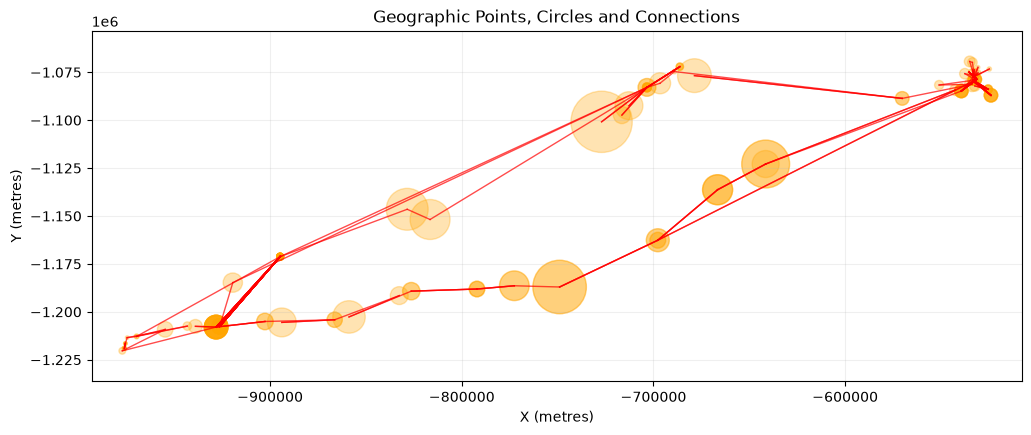

In [50]:

sub_data = data[data["distances"] > data["margin_error"]]

latitude, longitude, outer_radius = sub_data["latitude"], sub_data["longitude"], sub_data["outer_radius"]

transformer = Transformer.from_crs("EPSG:4326", "EPSG:5514", always_xy=True) #input, output

x_vals, y_vals = transformer.transform(longitude, latitude)

fig, ax = plt.subplots(figsize=(12, 10))

for i in range(len(sub_data)-1):

    x, y, r = x_vals[i], y_vals[i], outer_radius.iloc[i]

    x_next, y_next, r_next = x_vals[i+1], y_vals[i+1], outer_radius.iloc[i+1]

    circle = plt.Circle((x, y), radius=r, facecolor="orange", alpha=0.3, edgecolor="orange")

    ax.add_patch(circle)

    ax.plot([x, x_next], [y, y_next], color="red", linewidth=1, alpha=0.7, zorder=2)

max_radius = outer_radius.max()

ax.set_xlim(min(x_vals) - max_radius, max(x_vals) + max_radius) #sets the x-axis value range
ax.set_ylim(min(y_vals) - max_radius, max(y_vals) + max_radius) #sets the y-axis value range

ax.set_aspect("equal")
ax.set_xlabel("X (metres)")
ax.set_ylabel("Y (metres)")
ax.set_title("Geographic Points, Circles and Connections")
ax.grid(alpha=0.2)

plt.show()
